3.2.2. Phân tích khám phá dữ liệu (EDA) – Dự báo nhu cầu QSR
Đề tài: Ứng dụng Machine Learning trong dự báo nhu cầu sản phẩm ngắn hạn và tối ưu tồn kho cho chuỗi nhà hàng phục vụ nhanh (QSR). Dữ liệu: 2026 HAVI – NIU Hackathon (15 nhà hàng × 50 món × 1.826 ngày, 01/01/2021 – 31/12/2025).

Mục tiêu của phần EDA :

Phân tích nhu cầu theo thời gian, nhà hàng (store) và sản phẩm (product).
So sánh ngày thường – cuối tuần.
Khảo sát quan hệ giữa lượng bán với promotion, holiday, special event, weather.
Rút ra kết luận để chọn đặc trưng cho mô hình CatBoost / LightGBM.

In [ ]:
import os, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Bảng màu thống nhất cho toàn bộ notebook (thứ tự cố định, không xoay vòng)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, GRAY = PALETTE[0], PALETTE[1], "#9a9994"
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "lines.linewidth": 1.6,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

FIG_DIR = "eda_figures"
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    """Lưu biểu đồ để chèn vào báo cáo."""
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")
    plt.show()

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Đang chạy trên Colab:", IN_COLAB)

Đang chạy trên Colab: True


In [ ]:
# ---- Chạy trên máy cá nhân (VS Code / Jupyter, Windows) ----
LOCAL_PATH = r"C:\machine learning\qsr_demand_dataset.csv"   # <-- đường dẫn file CSV trên máy bạn

# ---- Chạy trên Google Colab ----
USE_DRIVE  = True
DRIVE_PATH = "/content/drive/MyDrive/qsr_demand_dataset.csv"   # <-- sửa lại nếu để ở thư mục khác trên Drive

DATA_PATH = os.environ.get("QSR_DATA_PATH", LOCAL_PATH)
if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        try:
            drive.mount("/content/drive")
        except Exception as e:
            print("Không thể kết nối Drive:", e)

        # Thử tìm file tự động trong Drive nếu không thấy ở DRIVE_PATH mặc định
        if not os.path.exists(DRIVE_PATH):
            import glob
            print(f"Không tìm thấy file tại: {DRIVE_PATH}")
            print("Đang tìm kiếm file *.csv trong Google Drive của bạn...")
            matches = glob.glob("/content/drive/MyDrive/**/*.csv", recursive=True)
            if matches:
                print("Tìm thấy các file CSV sau đây trong Drive của bạn:")
                for m in matches:
                    print(f" - {m}")
                # Tự động chọn file đầu tiên tìm thấy phù hợp tên
                qsr_matches = [m for m in matches if "qsr" in m.lower()]
                if qsr_matches:
                    DRIVE_PATH = qsr_matches[0]
                    print(f"-> Tự động chọn đường dẫn tìm thấy: {DRIVE_PATH}")

        # Nếu file không tồn tại trên Drive nhưng có sẵn ở thư mục hiện tại (Colab workspace)
        if os.path.exists("qsr_demand_dataset.csv") and not os.path.exists(DRIVE_PATH):
            DATA_PATH = "qsr_demand_dataset.csv"
        else:
            DATA_PATH = DRIVE_PATH
    else:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
elif not os.path.exists(DATA_PATH) and os.path.exists("qsr_demand_dataset.csv"):
    DATA_PATH = "qsr_demand_dataset.csv"   # file nằm cùng thư mục với notebook

print("Đọc dữ liệu từ:", DATA_PATH)

try:
    df = pd.read_csv(DATA_PATH, parse_dates=["date"])
    # Đổi cột chuỗi sang 'category' để tiết kiệm RAM (Colab free ~12 GB)
    for c in ["restaurant_id", "restaurant_name", "city", "state", "menu_item_id",
              "menu_item_name", "category", "day_of_week", "precip_type", "holiday_name", "special_event_name"]:
        if c in df.columns:
            df[c] = df[c].astype("category")
    print(df.shape)
    print(f"RAM: {df.memory_usage(deep=True).sum()/1e6:,.0f} MB")
    display(df.head())
except FileNotFoundError as e:
    print("\n[LỖI THIẾU FILE] Không thể mở file dữ liệu. Vui lòng tải file lên Google Drive hoặc kéo thả trực tiếp vào thư mục hiện tại của Colab.")
    print("Chi tiết lỗi:", e)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Không tìm thấy file tại: /content/drive/MyDrive/qsr_demand_dataset.csv
Đang tìm kiếm file *.csv trong Google Drive của bạn...
Đọc dữ liệu từ: qsr_demand_dataset.csv
(161662, 23)
RAM: 17 MB


,date,restaurant_id,restaurant_name,city,state,menu_item_id,menu_item_name,category,unit_price,quantity,day_of_week,day_of_week_num,is_weekend,month,year,avg_temp_f,precip_inches,precip_type,is_holiday,holiday_name,is_special_event,special_event_name,is_promotion
0,2021-01-01,R01,Downtown Chicago Grill,Chicago,IL,M01,Classic Cheeseburger,Burgers,6.990,75.000,Friday,4,0,1,2021,24.300,0.000,NaN,1.000,New Year's Day,0.000,NaN,0.000
1,2021-01-01,R01,Downtown Chicago Grill,Chicago,IL,M02,Double Bacon Burger,Burgers,9.490,45.000,Friday,4,0,1,2021,24.300,0.000,NaN,1.000,New Year's Day,0.000,NaN,0.000
2,2021-01-01,R01,Downtown Chicago Grill,Chicago,IL,M03,Veggie Burger,Burgers,7.490,24.000,Friday,4,0,1,2021,24.300,0.000,NaN,1.000,New Year's Day,0.000,NaN,0.000
3,2021-01-01,R01,Downtown Chicago Grill,Chicago,IL,M04,Mushroom Swiss Burger,Burgers,8.290,34.000,Friday,4,0,1,2021,24.300,0.000,NaN,1.000,New Year's Day,0.000,NaN,0.000
4,2021-01-01,R01,Downtown Chicago Grill,Chicago,IL,M05,BBQ Ranch Burger,Burgers,8.990,27.000,Friday,4,0,1,2021,24.300,0.000,NaN,1.000,New Year's Day,0.000,NaN,0.000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. Tổng quan cấu trúc dữ liệu

In [ ]:
print("Khoảng thời gian :", df.date.min().date(), "→", df.date.max().date(), f"({df.date.nunique()} ngày)")
print("Số nhà hàng      :", df.restaurant_id.nunique())
print("Số món           :", df.menu_item_id.nunique())
print("Số chuỗi (store×item):", df.groupby(["restaurant_id", "menu_item_id"], observed=True).ngroups)
print("Kỳ vọng số dòng  :", df.date.nunique() * df.restaurant_id.nunique() * df.menu_item_id.nunique(), "| Thực tế:", len(df))
df.describe().T

Khoảng thời gian : 2021-01-01 → 2025-12-31 (1826 ngày)
Số nhà hàng      : 2
Số món           : 50
Số chuỗi (store×item): 100
Kỳ vọng số dòng  : 182600 | Thực tế: 161662


,count,mean,min,25%,50%,75%,max,std
date,161662,2023-04-02 08:51:36.950426880,2021-01-01 00:00:00,2022-02-09 00:00:00,2023-03-20 00:00:00,2024-04-27 00:00:00,2025-12-31 00:00:00,NaN
unit_price,"161,662.000",5.312,1.490,2.990,4.990,7.490,12.490,2.694
quantity,"161,025.000",31.433,0.000,19.000,26.000,39.000,"1,050.000",20.877
day_of_week_num,"161,662.000",3.000,0.000,1.000,3.000,5.000,6.000,2.000
is_weekend,"161,662.000",0.286,0.000,0.000,0.000,1.000,1.000,0.452
month,"161,662.000",6.439,1.000,3.000,6.000,9.000,12.000,3.414
year,"161,662.000","2,022.747",202.000,"2,022.000","2,023.000","2,024.000","2,025.000",4.716
avg_temp_f,"161,661.000",51.994,16.800,35.900,53.000,68.800,79.600,17.602
precip_inches,"161,661.000",0.097,0.000,0.000,0.000,0.080,2.970,0.245
is_holiday,"161,661.000",0.035,0.000,0.000,0.000,0.000,1.000,0.183




> Add blockquote
print("Khoảng thời gian :", df.date.min().date(), "→", df.date.max().date(), f"({df.date.nunique()} ngày)")
print("Số nhà hàng      :", df.restaurant_id.nunique())
print("Số món           :", df.menu_item_id.nunique())
print("Số chuỗi (store×item):", df.groupby(["restaurant_id", "menu_item_id"], observed=True).ngroups)
print("Kỳ vọng số dòng  :", df.date.nunique() * df.restaurant_id.nunique() * df.menu_item_id.nunique(), "| Thực tế:", len(df))
df.describe().T



2.Làm sạch nhanh trươc khi phân tích

In [ ]:
key = ["date", "restaurant_id", "menu_item_id"]
span = df.groupby(["restaurant_id", "menu_item_id"], observed=True).date.agg(["min", "max", "count"])
print("Trùng khoá (date,store,item):", df.duplicated(key).sum())
print("Chuỗi bị khuyết ngày        :", ((span["max"] - span["min"]).dt.days + 1 != span["count"]).sum(), "/", len(span))
print(f"quantity thiếu              : {df.quantity.isna().sum():,} dòng ({df.quantity.isna().mean():.2%})")
print(f"quantity = 0                : {(df.quantity == 0).sum():,} dòng ({(df.quantity == 0).mean():.2%})")

# Outlier theo từng chuỗi store×item×thứ: robust z-score (median & MAD)
grp = df.groupby(["restaurant_id", "menu_item_id", "day_of_week_num"], observed=True).quantity
med = grp.transform("median")
mad = grp.transform(lambda s: (s - s.median()).abs().median()).replace(0, 1)
df["is_outlier"] = ((df.quantity - med) / (1.4826 * mad) > 6).astype(int)
print(f"Outlier (robust z > 6)      : {df.is_outlier.sum():,} dòng ({df.is_outlier.mean():.3%}), max = {df.quantity.max():,.0f}")

Trùng khoá (date,store,item): 0
Chuỗi bị khuyết ngày        : 0 / 100
quantity thiếu              : 637 dòng (0.39%)
quantity = 0                : 3,414 dòng (2.11%)
Outlier (robust z > 6)      : 570 dòng (0.353%), max = 1,050


Nhận xét. Không có dòng trùng, đủ 750 chuỗi × 1.826 ngày liên tục. quantity thiếu ~0,4% (ngẫu nhiên) và có ~0,37% đỉnh dị biệt ⇒ nội suy trong từng chuỗi và cap outlier thay vì xoá dòng, để không làm đứt chuỗi thời gian.




### 2.4 Quy ước làm sạch dùng cho phần còn lại của EDA
- Biến `quantity_clean`: các giá trị outlier được **cắt trần (cap)** về `median + 6·1.4826·MAD` của chuỗi, giá trị thiếu được **nội suy tuyến tính trong từng chuỗi**. Dữ liệu gốc vẫn giữ nguyên ở `quantity`.
- Để so sánh công bằng giữa các nhà hàng/món có quy mô khác nhau, ta dùng **chỉ số nhu cầu (demand index)**:
  `demand_index = quantity_clean / baseline`, trong đó `baseline` = trung bình của cùng *nhà hàng × món × thứ* tính trên **ngày bình thường** (không promo, không lễ, không sự kiện).
  ⇒ `demand_index = 1.20` nghĩa là bán cao hơn 20% so với một ngày bình thường cùng thứ. Cách này loại bỏ được ảnh hưởng gây nhiễu của quy mô cửa hàng, loại món và thứ trong tuần.
- Vì nhu cầu có **mùa vụ rất mạnh** (mùa hè cao hơn mùa đông), khi đo tác động của promotion/holiday/event/mưa ta dùng thêm `demand_index_m` với baseline tính theo *nhà hàng × món × thứ × **tháng***. Nếu không, một sự kiện rơi vào mùa hè sẽ trông như có "lift" chỉ vì mùa hè vốn bán nhiều.

In [ ]:
df = df.sort_values(["restaurant_id", "menu_item_id", "date"]).reset_index(drop=True)
grp = df.groupby(["restaurant_id", "menu_item_id", "day_of_week_num"], observed=True).quantity
med = grp.transform("median")
mad = grp.transform(lambda s: (s - s.median()).abs().median()).replace(0, 1)
upper = med + 6 * 1.4826 * mad
df["quantity_clean"] = df.quantity.clip(upper=upper)
df["quantity_clean"] = (df.groupby(["restaurant_id", "menu_item_id"], observed=True).quantity_clean
                          .transform(lambda s: s.interpolate(limit_direction="both")))

df["normal_day"] = ((df.is_promotion == 0) & (df.is_holiday == 0) & (df.is_special_event == 0)).astype(int)
base = (df[df.normal_day == 1].groupby(["restaurant_id", "menu_item_id", "day_of_week_num"], observed=True)
          .quantity_clean.mean().rename("baseline"))
df = df.join(base, on=["restaurant_id", "menu_item_id", "day_of_week_num"])
df["demand_index"] = df.quantity_clean / df.baseline.replace(0, np.nan)

base_m = (df[df.normal_day == 1].groupby(["restaurant_id", "menu_item_id", "day_of_week_num", "month"], observed=True)
            .quantity_clean.mean().rename("baseline_m"))
df = df.join(base_m, on=["restaurant_id", "menu_item_id", "day_of_week_num", "month"])
df["demand_index_m"] = df.quantity_clean / df.baseline_m.replace(0, np.nan)
print("Còn thiếu sau làm sạch:", df.quantity_clean.isna().sum())
df[["quantity", "quantity_clean", "baseline", "demand_index", "demand_index_m"]].describe().T

Còn thiếu sau làm sạch: 0


,count,mean,std,min,25%,50%,75%,max
quantity,"161,025.000",31.433,20.877,0.000,19.000,26.000,39.000,"1,050.000"
quantity_clean,"161,662.000",31.245,19.587,0.000,19.000,26.000,39.000,301.599
baseline,"161,662.000",30.346,15.715,8.384,18.975,26.962,36.649,108.422
demand_index,"161,662.000",1.030,0.340,0.000,0.831,1.003,1.205,3.590
demand_index_m,"161,662.000",1.024,0.265,0.000,0.905,1.020,1.144,5.527


3.Nhu cầu theo thời gian

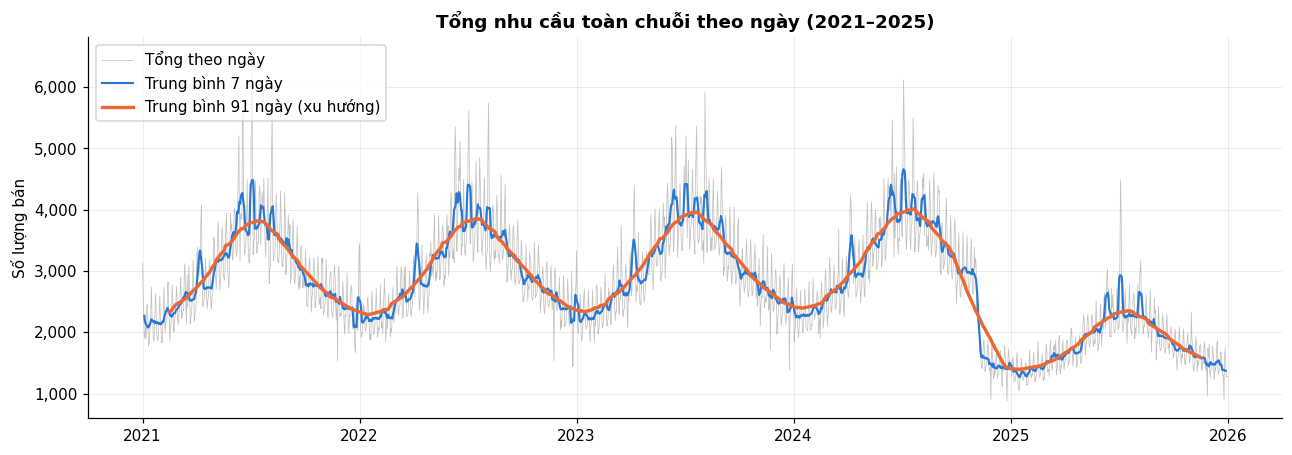

Tổng theo năm:
 year
202            25
2021    1,079,464
2022    1,096,439
2023    1,127,351
2024    1,085,692
2025      662,189
Name: quantity_clean, dtype: object
Tăng trưởng YoY:
 year
2021    4317754.03%
2022          1.57%
2023          2.82%
2024          -3.7%
2025        -39.01%
Name: quantity_clean, dtype: object


In [ ]:
daily = df.groupby("date").quantity_clean.sum()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily.index, daily, color=GRAY, lw=0.5, alpha=0.6, label="Tổng theo ngày")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color=BLUE, lw=1.4, label="Trung bình 7 ngày")
ax.plot(daily.index, daily.rolling(91, center=True).mean(), color=ORANGE, lw=2.2, label="Trung bình 91 ngày (xu hướng)")
ax.set_title("Tổng nhu cầu toàn chuỗi theo ngày (2021–2025)"); ax.set_ylabel("Số lượng bán"); ax.legend(loc="upper left")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save(fig, "01_daily_total_trend")

yearly = df.groupby("year").quantity_clean.sum()
print("Tổng theo năm:\n", yearly.map("{:,.0f}".format))
print("Tăng trưởng YoY:\n", (yearly.pct_change() * 100).round(2).dropna().astype(str) + "%")

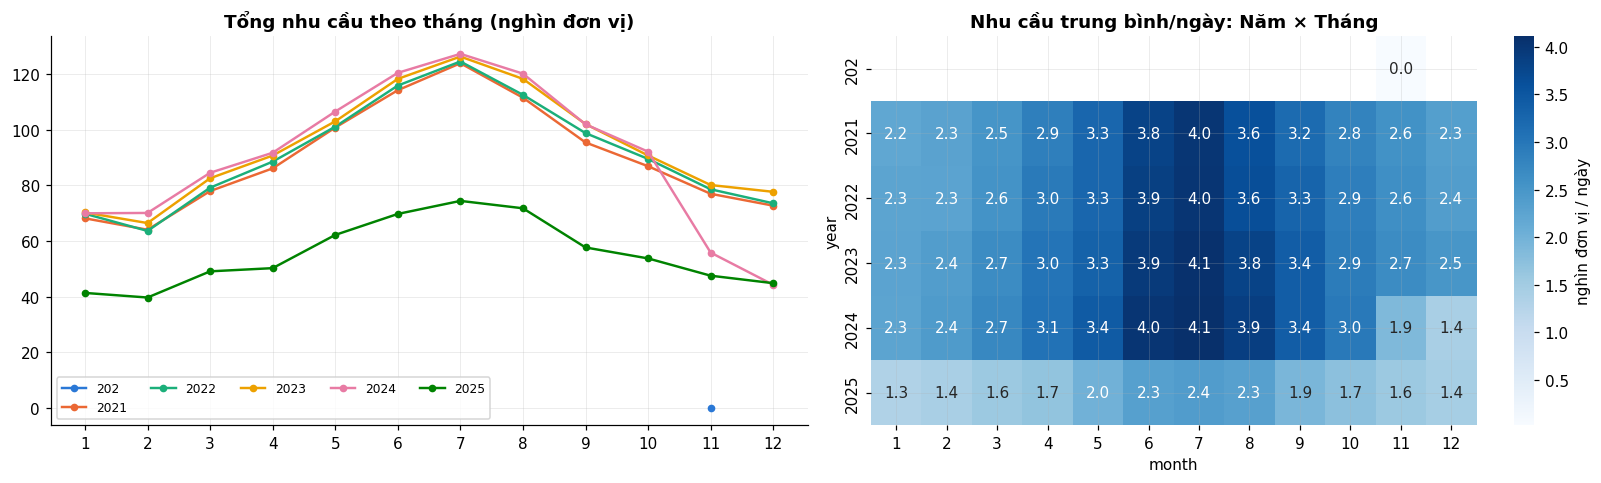

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
m = df.groupby(["year", "month"]).quantity_clean.sum().unstack(0) / 1e3
for i, y in enumerate(m.columns):
    ax[0].plot(m.index, m[y], marker="o", ms=4, color=PALETTE[i], label=str(y))
ax[0].set_xticks(range(1, 13)); ax[0].set_title("Tổng nhu cầu theo tháng (nghìn đơn vị)"); ax[0].legend(ncol=5, fontsize=8)

# Chuẩn hoá theo số ngày trong tháng để so sánh mùa vụ công bằng
mpd = df.groupby(["year", "month"]).agg(q=("quantity_clean", "sum"), d=("date", "nunique"))
heat = (mpd.q / mpd.d).unstack("month") / 1e3
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".1f", ax=ax[1], cbar_kws={"label": "nghìn đơn vị / ngày"})
ax[1].set_title("Nhu cầu trung bình/ngày: Năm × Tháng")
plt.tight_layout(); save(fig, "02_monthly_seasonality")

Nhận xét. Nhu cầu có tính mùa vụ năm rất mạnh. Xu hướng dài hạn tăng nhẹ và đều ~1,7–2,1%/năm. Đường tổng theo ngày còn có dao động răng cưa đều đặn theo tuần. ⇒ Đặc trưng cần có: month, week_of_year, day_of_year (hoặc dạng sin/cos), và một biến xu hướng (year hoặc số ngày từ đầu chuỗi). Dao động răng cưa theo tuần cho thấy cần các biến trễ theo bội số 7 ngày (lag_7, lag_14, lag_28), sẽ được kiểm chứng ở bước Feature Engineering. Lưu ý cây quyết định (LightGBM/CatBoost) không ngoại suy được xu hướng, nên lag/rolling sẽ giúp mô hình "bắt" mức tăng mới nhất.

4. Ngày thường vs. cuối tuần


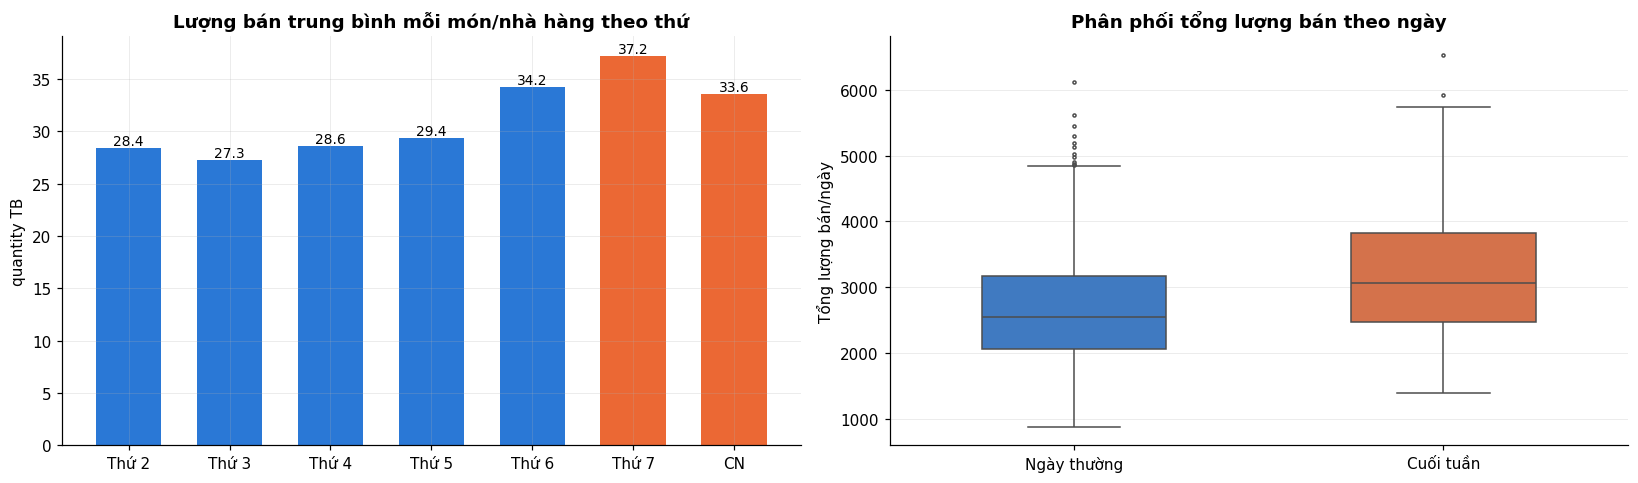

Cuối tuần cao hơn ngày thường: +19.7%   (Mann-Whitney U p-value = 8.04e-26)
Thứ 7 so với Thứ 3 (thấp nhất): +36.4%


In [ ]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
vn = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "CN"]
dow = df.groupby("day_of_week", observed=True).quantity_clean.mean().reindex(order)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(vn, dow.values, color=[ORANGE if d in ("Saturday", "Sunday") else BLUE for d in order], width=0.65)
for i, v in enumerate(dow.values):
    ax[0].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Lượng bán trung bình mỗi món/nhà hàng theo thứ"); ax[0].set_ylabel("quantity TB")

# Tổng theo ngày của toàn chuỗi – phân phối ngày thường vs cuối tuần
dd = df.groupby(["date", "is_weekend"]).quantity_clean.sum().reset_index()
sns.boxplot(data=dd, x="is_weekend", y="quantity_clean", ax=ax[1], palette=[BLUE, ORANGE], width=0.5, fliersize=2)
ax[1].set_xticklabels(["Ngày thường", "Cuối tuần"]); ax[1].set_xlabel(""); ax[1].set_ylabel("Tổng lượng bán/ngày")
ax[1].set_title("Phân phối tổng lượng bán theo ngày")
plt.tight_layout(); save(fig, "03_weekday_weekend")

wk, we = dd[dd.is_weekend == 0].quantity_clean, dd[dd.is_weekend == 1].quantity_clean
t, p = stats.mannwhitneyu(we, wk)
print(f"Cuối tuần cao hơn ngày thường: {we.mean()/wk.mean()-1:+.1%}   (Mann-Whitney U p-value = {p:.2e})")
print(f"Thứ 7 so với Thứ 3 (thấp nhất): {dow['Saturday']/dow.min()-1:+.1%}")

Nhận xét. Cuối tuần bán cao hơn ngày thường +19,5% (kiểm định Mann-Whitney p ≈ 1e-50). Thứ tự rõ ràng: Thứ 7 cao nhất (chỉ số 1,19), Thứ 6 1,10, CN 1,07; Thứ 3 thấp nhất (0,87) – Thứ 7 cao hơn Thứ 3 khoảng 36%. ⇒ Dùng day_of_week (7 mức) thay vì chỉ is_weekend vì Thứ 6 cũng cao và CN thấp hơn Thứ 7; không cần tạo đặc trưng tương tác store×thứ.

5.Nhu cầu theo nhà hàng (store)


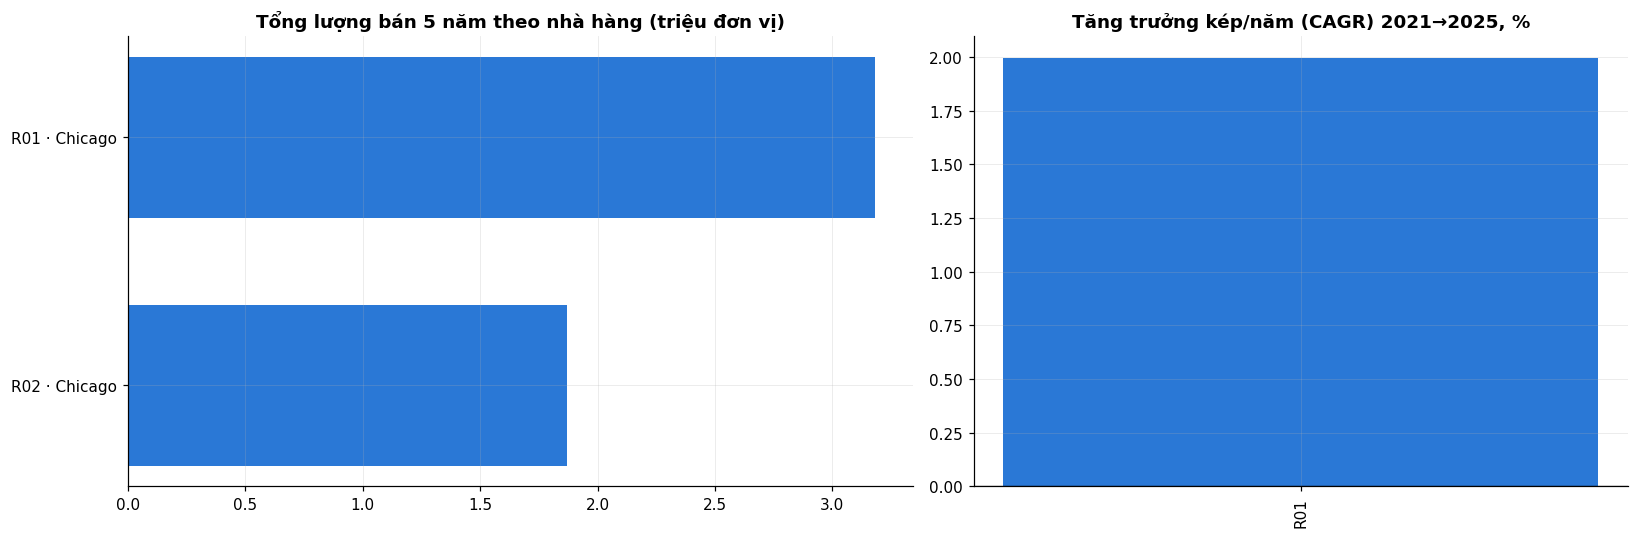

Nhà hàng lớn nhất / nhỏ nhất: 1.70 lần


,restaurant_id,restaurant_name,city,total,mean_per_item_day,share_%
0,R01,Downtown Chicago Grill,Chicago,"3,183,101.517",34.864,63.017
1,R02,Wrigleyville Bites,Chicago,"1,868,058.680",26.549,36.983


In [ ]:
st = (df.groupby(["restaurant_id", "restaurant_name", "city"], observed=True)
        .agg(total=("quantity_clean", "sum"), mean_per_item_day=("quantity_clean", "mean"))
        .sort_values("total", ascending=False).reset_index())
st["share_%"] = st.total / st.total.sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})
lbl = [f"{r} · {c}" for r, c in zip(st.restaurant_id.astype(str), st.city.astype(str))]
ax[0].barh(lbl[::-1], st.total.values[::-1] / 1e6, color=BLUE, height=0.65)
ax[0].set_title("Tổng lượng bán 5 năm theo nhà hàng (triệu đơn vị)")

sy = df.groupby(["restaurant_id", "year"], observed=True).quantity_clean.sum().unstack()
growth = (sy[2025] / sy[2021]) ** (1/4) - 1
ax[1].bar(growth.index.astype(str), growth.values * 100, color=[BLUE if g >= 0 else ORANGE for g in growth], width=0.65)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("Tăng trưởng kép/năm (CAGR) 2021→2025, %"); ax[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); save(fig, "04_store_totals")
print(f"Nhà hàng lớn nhất / nhỏ nhất: {st.total.max()/st.total.min():.2f} lần")
st

Nhận xét. Quy mô nhà hàng chênh nhau 2 lần: R01 Downtown Chicago lớn nhất (9,2% tổng lượng bán), nhóm nhỏ nhất là R12 Des Moines, R13 Omaha, R10 Cleveland, R14 Madison (~4,6–4,9%). Tốc độ tăng trưởng lại rất đồng đều (1,8–2,0%/năm ở mọi nhà hàng). ⇒ Khác biệt giữa các nhà hàng chủ yếu là mức (level), nên restaurant_id (biến phân loại – CatBoost xử lý trực tiếp) cùng với các rolling mean theo chuỗi là đủ; city/state gần như trùng thông tin với restaurant_id (14 thành phố/15 nhà hàng) nên có thể bỏ.



6. Nhu cầu theo sản phẩm (product)

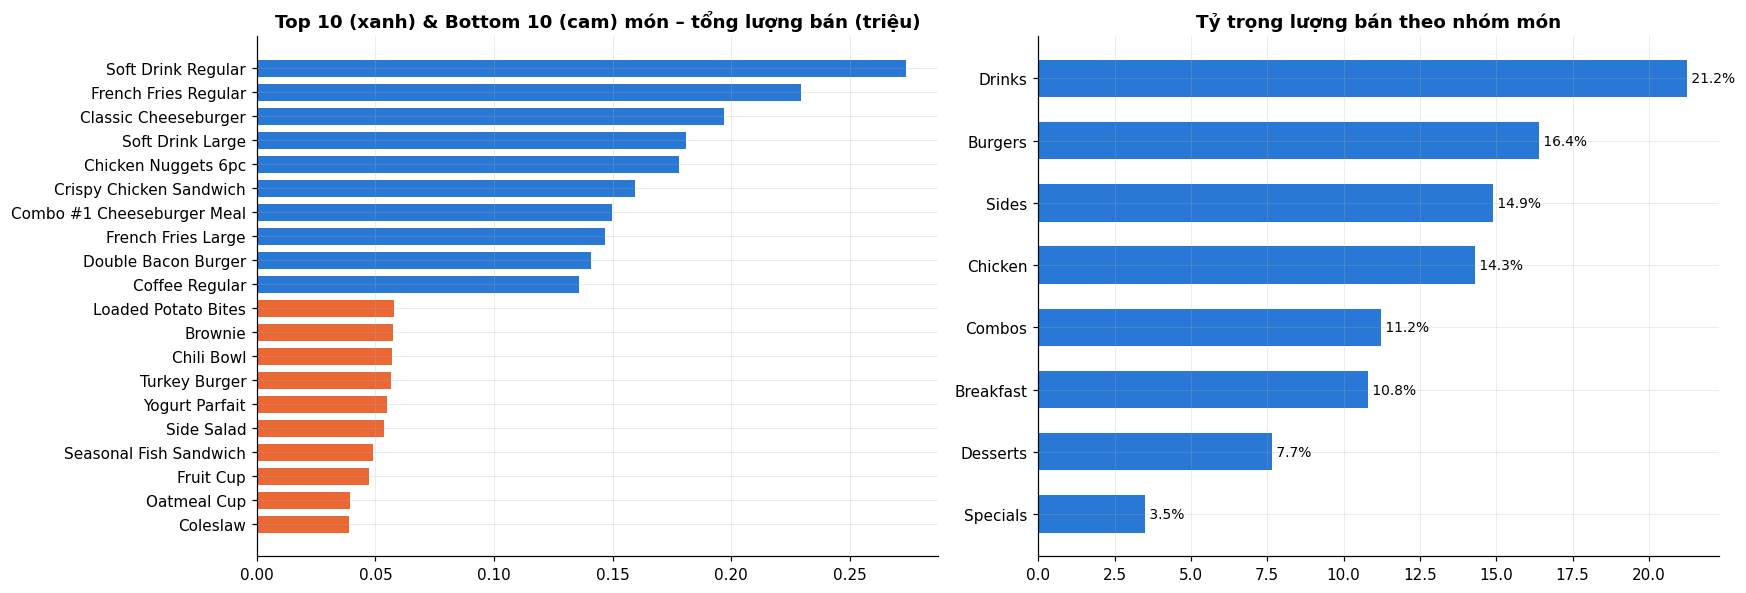

In [ ]:
it = (df.groupby(["menu_item_id", "menu_item_name", "category"], observed=True)
        .agg(total=("quantity_clean", "sum"), mean=("quantity_clean", "mean"), std=("quantity_clean", "std"),
             zero_rate=("quantity_clean", lambda s: (s == 0).mean()), price=("unit_price", "median"))
        .reset_index().sort_values("total", ascending=False))
it["cv"] = it["std"] / it["mean"]

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))

# Đảo thứ tự một lần cho cả bảng để Top 10 nằm phía trên trục
top = pd.concat([it.head(10), it.tail(10)]).iloc[::-1]
colors = [ORANGE] * 10 + [BLUE] * 10   # sau khi đảo: 10 dòng đầu là Bottom (cam), 10 dòng sau là Top (xanh)
ax[0].barh(top.menu_item_name.astype(str), top.total / 1e6, color=colors, height=0.7)
ax[0].set_title("Top 10 (xanh) & Bottom 10 (cam) món – tổng lượng bán (triệu)")

cat = df.groupby("category", observed=True).quantity_clean.sum().sort_values()
ax[1].barh(cat.index.astype(str), cat / cat.sum() * 100, color=BLUE, height=0.6)
for i, v in enumerate(cat / cat.sum() * 100):
    ax[1].text(v, i, f" {v:.1f}%", va="center", fontsize=9)
ax[1].set_title("Tỷ trọng lượng bán theo nhóm món")

plt.tight_layout(); save(fig, "05_product_top_bottom")

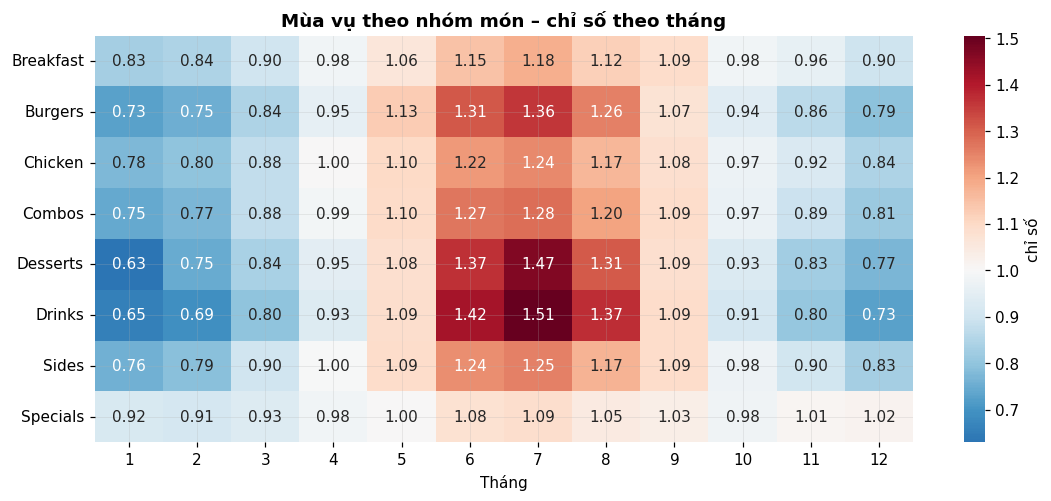

In [ ]:
# Mùa vụ theo nhóm món: chỉ số theo tháng (1 = trung bình năm của nhóm đó)
cm = df.groupby(["category", "month"], observed=True).quantity_clean.mean().unstack()
cm = cm.div(cm.mean(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(cm, cmap="RdBu_r", center=1, annot=True, fmt=".2f", ax=ax, cbar_kws={"label": "chỉ số"})
ax.set_title("Mùa vụ theo nhóm món – chỉ số theo tháng"); ax.set_ylabel(""); ax.set_xlabel("Tháng")
save(fig, "06_category_month_seasonality")

> **Nhận xét.** Món là yếu tố phân hoá mạnh nhất về quy mô: **Soft Drink Regular ~68 đơn vị/ngày**, French Fries Regular 58, Classic Cheeseburger 49, trong khi Coleslaw/Oatmeal Cup chỉ 10 (chênh 7 lần). Drinks chiếm **21%** tổng lượng bán, Burgers 16%, Sides 15%; Specials chỉ 3,5%. Món bán ít có **độ biến động tương đối (CV) cao hơn** và tỷ lệ ngày bán 0 cao hơn (~8%) ⇒ khó dự báo hơn, sai số % (wMAPE) sẽ lớn ở các món này. Mùa vụ khác nhau theo nhóm: **Drinks và Desserts dao động mạnh nhất** (tháng 7 ≈ 1,46–1,49 so với tháng 1 ≈ 0,63–0,66), Breakfast nhẹ hơn và **Specials gần như phẳng**. ⇒ Cần `menu_item_id` + `category` làm biến phân loại; mô hình cây sẽ tự học tương tác category × month.

7. Khuyến mãi (promotion)

Tỷ lệ dòng có khuyến mãi: 1.19%
Số món từng được KM: 50 | Số nhà hàng có KM: 2
Số món được KM trong cùng 1 store-ngày: {'mean': 2.7777777777777777, 'max': 8.0}

Lift do khuyến mãi (đã khử store/món/thứ/tháng): +24.9%
Mann-Whitney U p-value = 0.00e+00


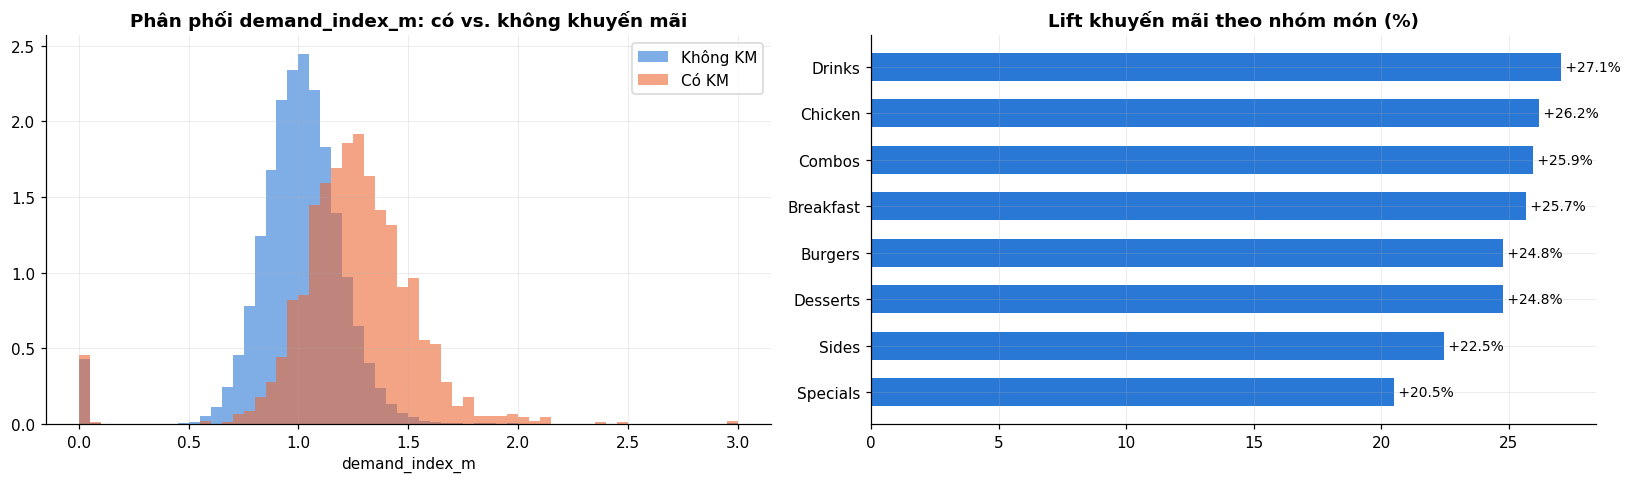

In [ ]:
print(f"Tỷ lệ dòng có khuyến mãi: {df.is_promotion.mean():.2%}")
pr = df[df.is_promotion == 1]
print("Số món từng được KM:", pr.menu_item_id.nunique(), "| Số nhà hàng có KM:", pr.restaurant_id.nunique())
print("Số món được KM trong cùng 1 store-ngày:", pr.groupby(["restaurant_id", "date"], observed=True).size().describe()[["mean", "max"]].to_dict())

# Lift = demand_index_m trung bình ngày KM (không lễ/sự kiện) so với ngày bình thường
clean_promo = df[(df.is_holiday == 0) & (df.is_special_event == 0)]
lift_all = clean_promo.groupby("is_promotion").demand_index_m.mean()
print(f"\nLift do khuyến mãi (đã khử store/món/thứ/tháng): {lift_all[1]/lift_all[0]-1:+.1%}")
t, p = stats.mannwhitneyu(clean_promo.loc[clean_promo.is_promotion == 1, "demand_index_m"].dropna(),
                          clean_promo.loc[clean_promo.is_promotion == 0, "demand_index_m"].dropna())
print(f"Mann-Whitney U p-value = {p:.2e}")

lift_cat = (clean_promo.groupby(["category", "is_promotion"], observed=True).demand_index_m.mean().unstack())
lift_cat = (lift_cat[1] / lift_cat[0] - 1).sort_values() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].hist(clean_promo.loc[clean_promo.is_promotion == 0, "demand_index_m"].clip(0, 3), bins=60, density=True, alpha=0.6, color=BLUE, label="Không KM")
ax[0].hist(clean_promo.loc[clean_promo.is_promotion == 1, "demand_index_m"].clip(0, 3), bins=60, density=True, alpha=0.6, color=ORANGE, label="Có KM")
ax[0].set_title("Phân phối demand_index_m: có vs. không khuyến mãi"); ax[0].legend(); ax[0].set_xlabel("demand_index_m")
ax[1].barh(lift_cat.index.astype(str), lift_cat.values, color=BLUE, height=0.6)
for i, v in enumerate(lift_cat.values):
    ax[1].text(v, i, f" {v:+.1f}%", va="center", fontsize=9)
ax[1].set_title("Lift khuyến mãi theo nhóm món (%)")
plt.tight_layout(); save(fig, "07_promotion_lift")

> **Nhận xét.** Khuyến mãi hiếm (**1,14%** số dòng, TB ~2,7 món/nhà hàng/ngày) nhưng tác động rất rõ: **+25% nhu cầu** sau khi đã khử ảnh hưởng nhà hàng/món/thứ/tháng (p ≈ 0), và mức tăng **đồng đều giữa các nhóm món (+24–26%)**. ⇒ `is_promotion` là đặc trưng ngoại sinh **bắt buộc**; vì phân phối lệch mạnh (ít ngày KM), có thể cân nhắc thêm `promo_count_store_day` (số món đang KM tại cửa hàng). Lưu ý: ngày KM phải được **biết trước** khi dự báo (KM được lên kế hoạch) nên không gây rò rỉ dữ liệu.

8. Ngày lễ (holiday)

Số ngày lễ trong 5 năm: 63
Lift trung bình ngày lễ: +15.1%


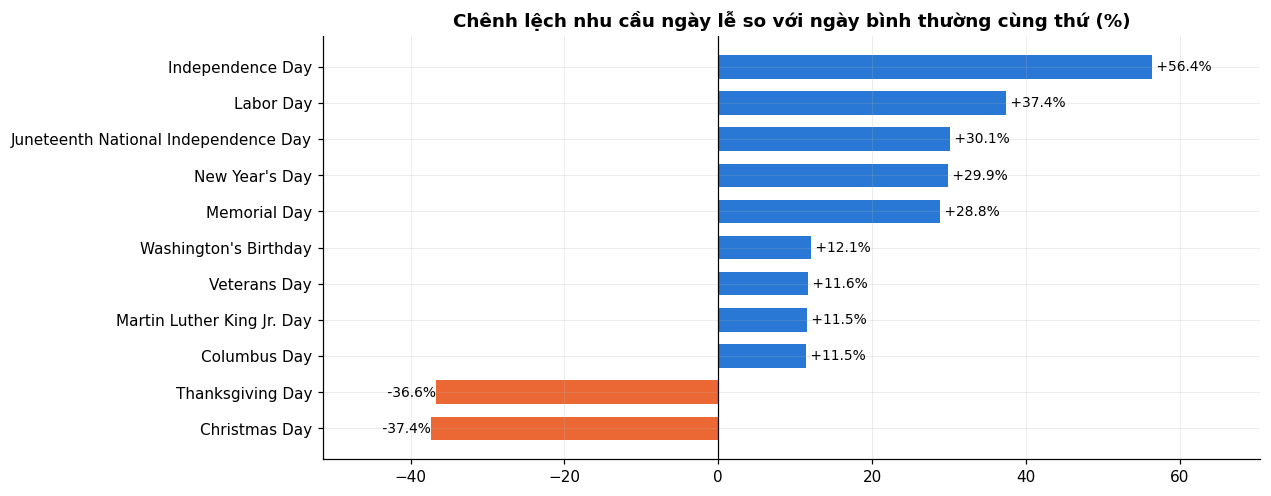

In [ ]:
print(f"Số ngày lễ trong 5 năm: {df.loc[df.is_holiday == 1, 'date'].nunique()}")
hol = df[(df.is_holiday == 1) & (df.is_promotion == 0)]
hname = hol.holiday_name.astype(str).str.replace(r" \(observed\)", "", regex=True)
lift_h = (hol.groupby(hname).demand_index_m.mean() - 1).sort_values() * 100
print(f"Lift trung bình ngày lễ: {hol.demand_index_m.mean() - 1:+.1%}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(lift_h.index, lift_h.values, color=[ORANGE if v < 0 else BLUE for v in lift_h.values], height=0.65)
ax.axvline(0, color="black", lw=0.8); ax.margins(x=0.15)
for i, v in enumerate(lift_h.values):
    ax.text(v, i, f" {v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_title("Chênh lệch nhu cầu ngày lễ so với ngày bình thường cùng thứ (%)")
save(fig, "08_holiday_lift")

Nhận xét. Trung bình ngày lễ bán cao hơn ~14%, nhưng hiệu ứng ngược chiều tuỳ ngày lễ: Independence Day (+47%), Labor Day (+42%), Juneteenth, Memorial Day, New Year's Day (+32–33%) tăng mạnh; trong khi Thanksgiving và Christmas giảm ~35%. ⇒ Cờ is_holiday đơn thuần sẽ "triệt tiêu" hai hiệu ứng trái dấu; nên dùng holiday_name làm biến phân loại (gộp các ngày (observed) về cùng tên) hoặc tạo holiday_type (tăng/giảm). Đặc biệt quan trọng vì giai đoạn dự báo Q4/2025 có Columbus Day, Veterans Day, Thanksgiving và Christmas.



9. Sự kiện địa phương

Tỷ lệ dòng có sự kiện: 3.56%
Sự kiện gắn với nhà hàng cụ thể (không phải toàn chuỗi): mỗi ngày sự kiện có 1.0 nhà hàng bị ảnh hưởng (TB)
Lift trung bình ngày sự kiện: +49.3%


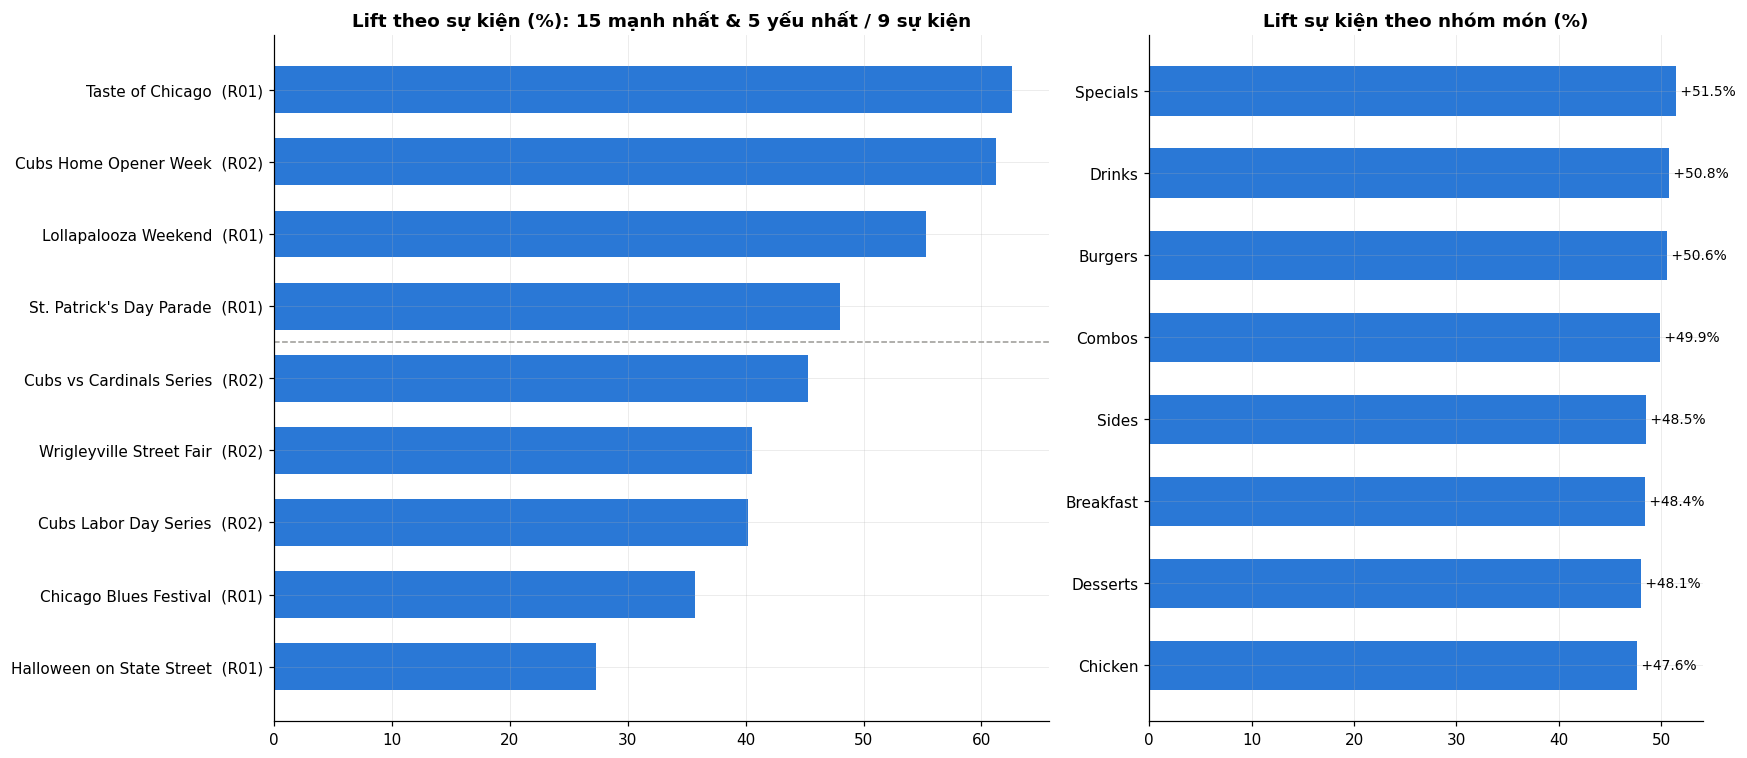

,lift,stores,days
special_event_name,,,
Taste of Chicago,62.601,R01,15
Cubs Home Opener Week,61.267,R02,24
Lollapalooza Weekend,55.313,R01,15
St. Patrick's Day Parade,48.017,R01,5
Cubs vs Cardinals Series,45.311,R02,12
Wrigleyville Street Fair,40.529,R02,12
Cubs Labor Day Series,40.170,R02,12
Chicago Blues Festival,35.717,R01,15
Halloween on State Street,27.298,R01,5


In [ ]:
evd = df[(df.is_special_event == 1) & (df.is_promotion == 0)]
print(f"Tỷ lệ dòng có sự kiện: {df.is_special_event.mean():.2%}")
print("Sự kiện gắn với nhà hàng cụ thể (không phải toàn chuỗi): mỗi ngày sự kiện có",
      df[df.is_special_event == 1].groupby("date").restaurant_id.nunique().mean().round(2), "nhà hàng bị ảnh hưởng (TB)")
print(f"Lift trung bình ngày sự kiện: {evd.demand_index_m.mean() - 1:+.1%}")

lift_e = (evd.groupby("special_event_name", observed=True)
             .agg(lift=("demand_index_m", lambda s: (s.mean() - 1) * 100),
                  stores=("restaurant_id", lambda s: ", ".join(sorted(s.astype(str).unique()))),
                  days=("date", "nunique"))
             .sort_values("lift"))
lift_e_plot = pd.concat([lift_e.head(5), lift_e.tail(15)])  # 15 sự kiện mạnh nhất + 5 yếu nhất cho dễ đọc
cat_e = (evd.groupby("category", observed=True).demand_index_m.mean() - 1).sort_values() * 100

fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.4, 1]})
ax[0].barh([f"{name}  ({stores})" for name, stores in zip(lift_e_plot.index.astype(str), lift_e_plot.stores)], lift_e_plot.lift,
           color=BLUE, height=0.65)
ax[0].axhline(4.5, color=GRAY, ls="--", lw=1)
ax[0].set_title(f"Lift theo sự kiện (%): 15 mạnh nhất & 5 yếu nhất / {len(lift_e)} sự kiện")
ax[1].barh(cat_e.index.astype(str), cat_e.values, color=BLUE, height=0.6)
for i, v in enumerate(cat_e.values):
    ax[1].text(v, i, f" {v:+.1f}%", va="center", fontsize=9)
ax[1].set_title("Lift sự kiện theo nhóm món (%)")
plt.tight_layout(); save(fig, "09_special_event_lift")
lift_e.sort_values("lift", ascending=False)

Nhận xét. Sự kiện địa phương là yếu tố ngoại sinh mạnh nhất: TB +48% nhu cầu (đã khử mùa vụ), dao động từ +21% (Thanksgiving Turkey Trot) đến ~+75% tuỳ sự kiện (Fourth of July Downtown Festival, KC Riverfest, Winter Classic Hockey… mạnh nhất). Mỗi sự kiện gắn với 1 nhà hàng cụ thể (TB 1,55 nhà hàng/ngày sự kiện), không ảnh hưởng toàn chuỗi. Mức tăng **đồng đều giữa các nhóm món (47–48%)** ⇒ sự kiện làm tăng lượng khách chung, không đổi cơ cấu món. Đây cũng là nguyên nhân của nhiều đỉnh dị biệt trong chuỗi. ⇒ Dùng is_special_event + special_event_name (CatBoost xử lý trực tiếp biến phân loại nhiều mức) và giữ cấp nhà hàng khi join vào bảng đặc trưng.

10. Thời tiết (weather)

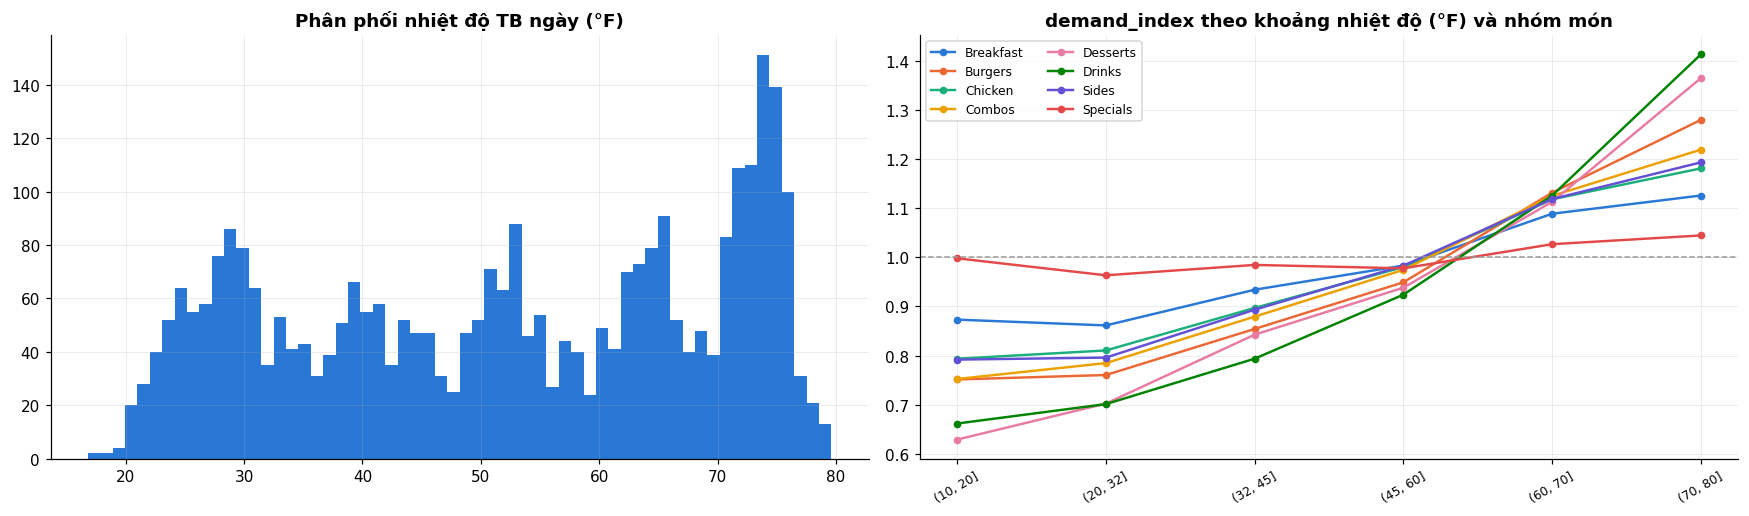

,"ρ(temp, demand_index)","ρ(temp, demand_index_m) – trong cùng tháng"
category,,
Breakfast,0.459,0.002
Burgers,0.723,0.007
Chicken,0.655,0.012
Combos,0.714,0.007
Desserts,0.762,0.024
Drinks,0.837,0.019
Sides,0.625,0.009
Specials,0.158,-0.000


In [ ]:
wd = df[df.normal_day == 1].copy()
wd["temp_bin"] = pd.cut(wd.avg_temp_f, bins=[-30, 10, 20, 32, 45, 60, 70, 80, 90, 120])
wd["precip_type"] = wd.precip_type.cat.add_categories("None").fillna("None")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].hist(df.drop_duplicates(["restaurant_id", "date"]).avg_temp_f, bins=60, color=BLUE)
ax[0].set_title("Phân phối nhiệt độ TB ngày (°F)")

tb = wd.groupby(["temp_bin", "category"], observed=True).demand_index.mean().unstack()
for i, c in enumerate(tb.columns):
    ax[1].plot(range(len(tb)), tb[c], marker="o", ms=4, color=PALETTE[i], label=str(c))
ax[1].set_xticks(range(len(tb))); ax[1].set_xticklabels([str(b) for b in tb.index], rotation=30, fontsize=8)
ax[1].axhline(1, color=GRAY, ls="--", lw=1)
ax[1].set_title("demand_index theo khoảng nhiệt độ (°F) và nhóm món"); ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); save(fig, "10_temperature")
rho = pd.DataFrame({
    "ρ(temp, demand_index)": wd.groupby("category", observed=True)[["avg_temp_f", "demand_index"]]
        .apply(lambda d: stats.spearmanr(d.avg_temp_f, d.demand_index, nan_policy="omit")[0]),
    # Sau khi khử mùa vụ (baseline theo tháng): nhiệt độ còn giải thích thêm được bao nhiêu?
    "ρ(temp, demand_index_m) – trong cùng tháng": wd.groupby("category", observed=True)[["avg_temp_f", "demand_index_m"]]
        .apply(lambda d: stats.spearmanr(d.avg_temp_f, d.demand_index_m, nan_policy="omit")[0]),
})
rho.round(3)

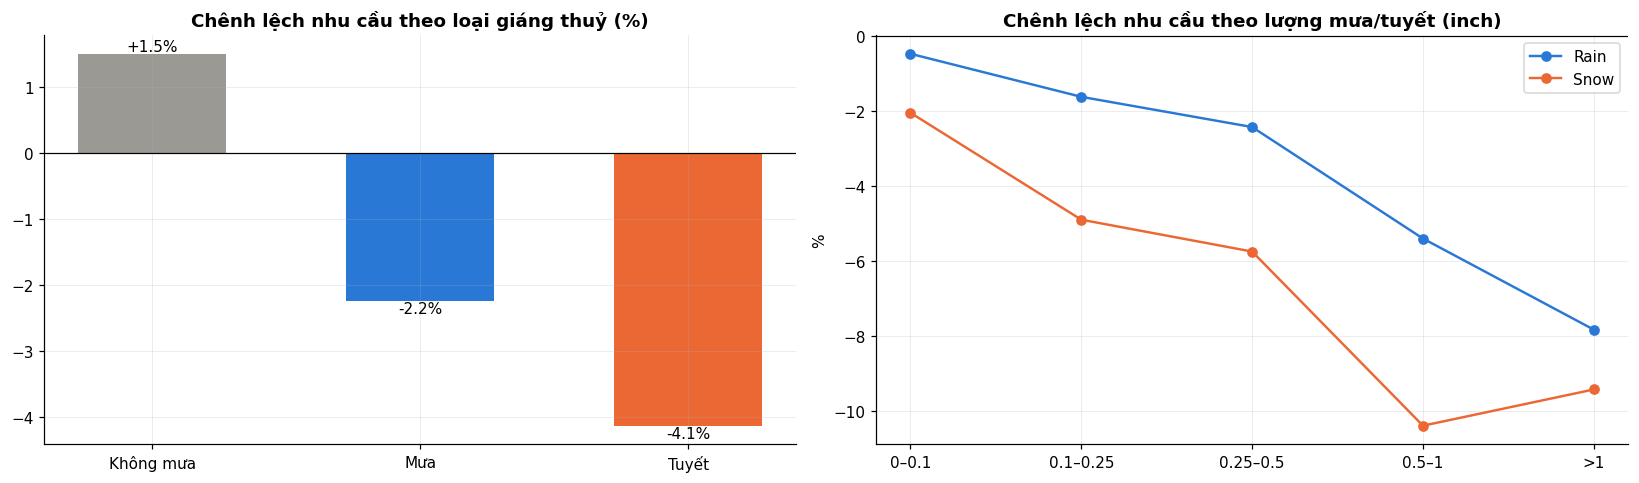

,mean,count
precip_type,,
None,1.015,96408
Rain,0.978,38315
Snow,0.959,14129


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
pt = wd.groupby("precip_type", observed=True).demand_index_m.agg(["mean", "count"]).reindex(["None", "Rain", "Snow"])
ax[0].bar(["Không mưa", "Mưa", "Tuyết"], (pt["mean"] - 1) * 100, color=[GRAY, BLUE, ORANGE], width=0.55)
for i, v in enumerate((pt["mean"] - 1) * 100):
    ax[0].text(i, v, f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=10)
ax[0].axhline(0, color="black", lw=0.8); ax[0].set_title("Chênh lệch nhu cầu theo loại giáng thuỷ (%)")

wd["precip_bin"] = pd.cut(wd.precip_inches, bins=[-0.01, 0, 0.1, 0.25, 0.5, 1, 5],
                          labels=["0", "0–0.1", "0.1–0.25", "0.25–0.5", "0.5–1", ">1"])
pb = wd.groupby(["precip_bin", "precip_type"], observed=True).demand_index_m.mean().unstack()
for c, col in [("Rain", BLUE), ("Snow", ORANGE)]:
    if c in pb:
        ax[1].plot(pb.index.astype(str), (pb[c] - 1) * 100, marker="o", color=col, label=c)
ax[1].axhline(0, color="black", lw=0.8); ax[1].legend()
ax[1].set_title("Chênh lệch nhu cầu theo lượng mưa/tuyết (inch)"); ax[1].set_ylabel("%")
plt.tight_layout(); save(fig, "11_precipitation")
pt

> **Nhận xét.** Nhiệt độ có tương quan rất mạnh với nhu cầu (ρ ≈ 0,6–0,8; mạnh nhất ở Drinks, Desserts), **nhưng khi so trong cùng một tháng thì tương quan gần như bằng 0** (ρ ≈ 0,01–0,03) ⇒ nhiệt độ chủ yếu là "đại diện" cho mùa vụ, không thêm nhiều thông tin ngoài `month`/`day_of_year`. Giáng thuỷ có tác động nhỏ nhưng rõ: **mưa −2%, tuyết −4%** so với ngày khô (sau khi khử mùa vụ), mưa/tuyết càng lớn giảm càng nhiều. ⇒ Giữ `precip_type`, `precip_inches` (và `avg_temp_f` như một biến phụ – SHAP sẽ cho biết mức đóng góp thật). Lưu ý thực tế: khi triển khai, thời tiết tương lai chỉ có ở dạng **dự báo thời tiết**, cần nêu rõ giả định này trong báo cáo.


11. Bảng tổng hợp mức độ ảnh hưởng của các yếu tố




In [ ]:
# Bảng tóm tắt hiệu ứng (đã khử quy mô store/món/thứ qua demand_index)
summary = pd.DataFrame({
    "Yếu tố": ["Cuối tuần (vs ngày thường)", "Khuyến mãi", "Ngày lễ (TB)", "Sự kiện địa phương", "Mưa", "Tuyết"],
    "Tỷ lệ ngày/dòng có": [df.is_weekend.mean(), df.is_promotion.mean(), df.is_holiday.mean(), df.is_special_event.mean(),
                         (df.precip_type == "Rain").mean(), (df.precip_type == "Snow").mean()],
    "Chênh lệch nhu cầu": [we.mean() / wk.mean() - 1, lift_all[1] / lift_all[0] - 1, hol.demand_index_m.mean() - 1,
                           evd.demand_index_m.mean() - 1, pt.loc["Rain", "mean"] - 1, pt.loc["Snow", "mean"] - 1],
})
summary.style.format({"Tỷ lệ ngày/dòng có": "{:.2%}", "Chênh lệch nhu cầu": "{:+.1%}"})

,Yếu tố,Tỷ lệ ngày/dòng có,Chênh lệch nhu cầu
0,Cuối tuần (vs ngày thường),28.58%,+19.7%
1,Khuyến mãi,1.19%,+24.9%
2,Ngày lễ (TB),3.46%,+15.1%
3,Sự kiện địa phương,3.56%,+49.3%
4,Mưa,25.52%,-2.2%
5,Tuyết,9.40%,-4.1%


## 12. Kết luận EDA & định hướng chọn đặc trưng

### Tóm tắt phát hiện chính

| # | Phát hiện | Bằng chứng | Hệ quả cho mô hình |
|---|---|---|---|
| 1 | Dữ liệu đầy đủ, thiếu 0,4% `quantity` ngẫu nhiên, ~0,37% đỉnh dị biệt, ~2% ngày bán 0 | Mục 2 | Nội suy trong chuỗi; cap outlier theo robust z; giữ số 0 |
| 2 | Mùa vụ năm mạnh (T7 ≈ 1,8× T1), xu hướng tăng ~2%/năm, dao động theo tuần | Mục 3 | `month`, `week_of_year`, `day_of_year`; lag/rolling theo bội số 7 ngày |
| 3 | Cuối tuần +19,5%; Thứ 7 cao nhất, Thứ 3 thấp nhất; mẫu hình giống nhau mọi store/món | Mục 4 | `day_of_week` (7 mức) + `is_weekend` |
| 4 | Store khác nhau ~2× về quy mô, tăng trưởng đồng đều | Mục 5 | `restaurant_id` (categorical); bỏ `city/state` |
| 5 | Món khác nhau ~7× về quy mô; mùa vụ khác theo nhóm | Mục 6 | `menu_item_id`, `category` (categorical); `unit_price` không cần |
| 6 | Promotion +25%, đồng đều, chỉ trong ngày | Mục 7 | `is_promotion` (bắt buộc) |
| 7 | Holiday ngược chiều: 4/7, Labor Day tăng; Thanksgiving, Christmas giảm ~35% | Mục 8 | `holiday_name` (categorical) thay vì chỉ `is_holiday` |
| 8 | Special event +48%, gắn theo từng nhà hàng | Mục 9 | `is_special_event`, `special_event_name` |
| 9 | Nhiệt độ ≈ mùa vụ; mưa −2%, tuyết −4% | Mục 10 | `precip_type`, `precip_inches`; `avg_temp_f` là biến phụ |

### Danh sách đặc trưng đề xuất cho bước 3.2.3
- **Định danh (categorical):** `restaurant_id`, `menu_item_id`, `category`
- **Lịch:** `day_of_week`, `is_weekend`, `month`, `week_of_year`, `day_of_year`, `year`
- **Lịch sử nhu cầu (tạo theo từng chuỗi, luôn `shift` trước khi `rolling` để chống leakage):** `lag_7`, `lag_14`, `lag_28` (+ `lag_1` nếu dự báo đệ quy, + `lag_364` nếu dự báo cả quý một lần), `roll_mean_7`, `roll_std_7`, `roll_mean_28`, `roll_std_28`
- **Ngoại sinh:** `is_promotion`, `holiday_name`, `is_special_event`, `special_event_name`, `precip_type`, `precip_inches`, `avg_temp_f`

### Chia tập theo thời gian (gợi ý)
Train: 2021-01-01 → 2024-12-31 · Validation: 2025-01-01 → 2025-06-30 · Test: 2025-07-01 → 2025-09-30 (hoặc dùng đúng giai đoạn 01/10–31/12/2025 làm test nếu có nhãn). Rolling/lag được tính trên toàn chuỗi đã sắp xếp theo thời gian *trước* khi cắt, nhưng chỉ dùng thông tin ≤ ngày t−1.

> Notebook lưu `qsr_clean.parquet` (dữ liệu đã làm sạch + `quantity_clean`, `is_outlier`) để dùng ngay cho bước Feature Engineering.

In [ ]:
# Lưu dữ liệu đã làm sạch để dùng cho bước 3.2.3 (Feature Engineering) – định dạng parquet nhẹ & nhanh
keep = ["date", "restaurant_id", "menu_item_id", "category", "city", "unit_price", "quantity", "quantity_clean",
        "is_outlier", "day_of_week_num", "is_weekend", "month", "year", "avg_temp_f", "precip_inches", "precip_type",
        "is_holiday", "holiday_name", "is_special_event", "special_event_name", "is_promotion"]
try:
    df[keep].to_parquet("qsr_clean.parquet", index=False)
    print("Đã lưu qsr_clean.parquet")
except Exception as e:
    print("Không lưu được parquet:", e)

with zipfile.ZipFile("eda_figures.zip", "w") as z:
    for f in sorted(os.listdir(FIG_DIR)):
        z.write(os.path.join(FIG_DIR, f))
print("Đã nén", len(os.listdir(FIG_DIR)), "biểu đồ vào eda_figures.zip")

if IN_COLAB:
    from google.colab import files
    files.download("eda_figures.zip")

Đã lưu qsr_clean.parquet
Đã nén 11 biểu đồ vào eda_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>